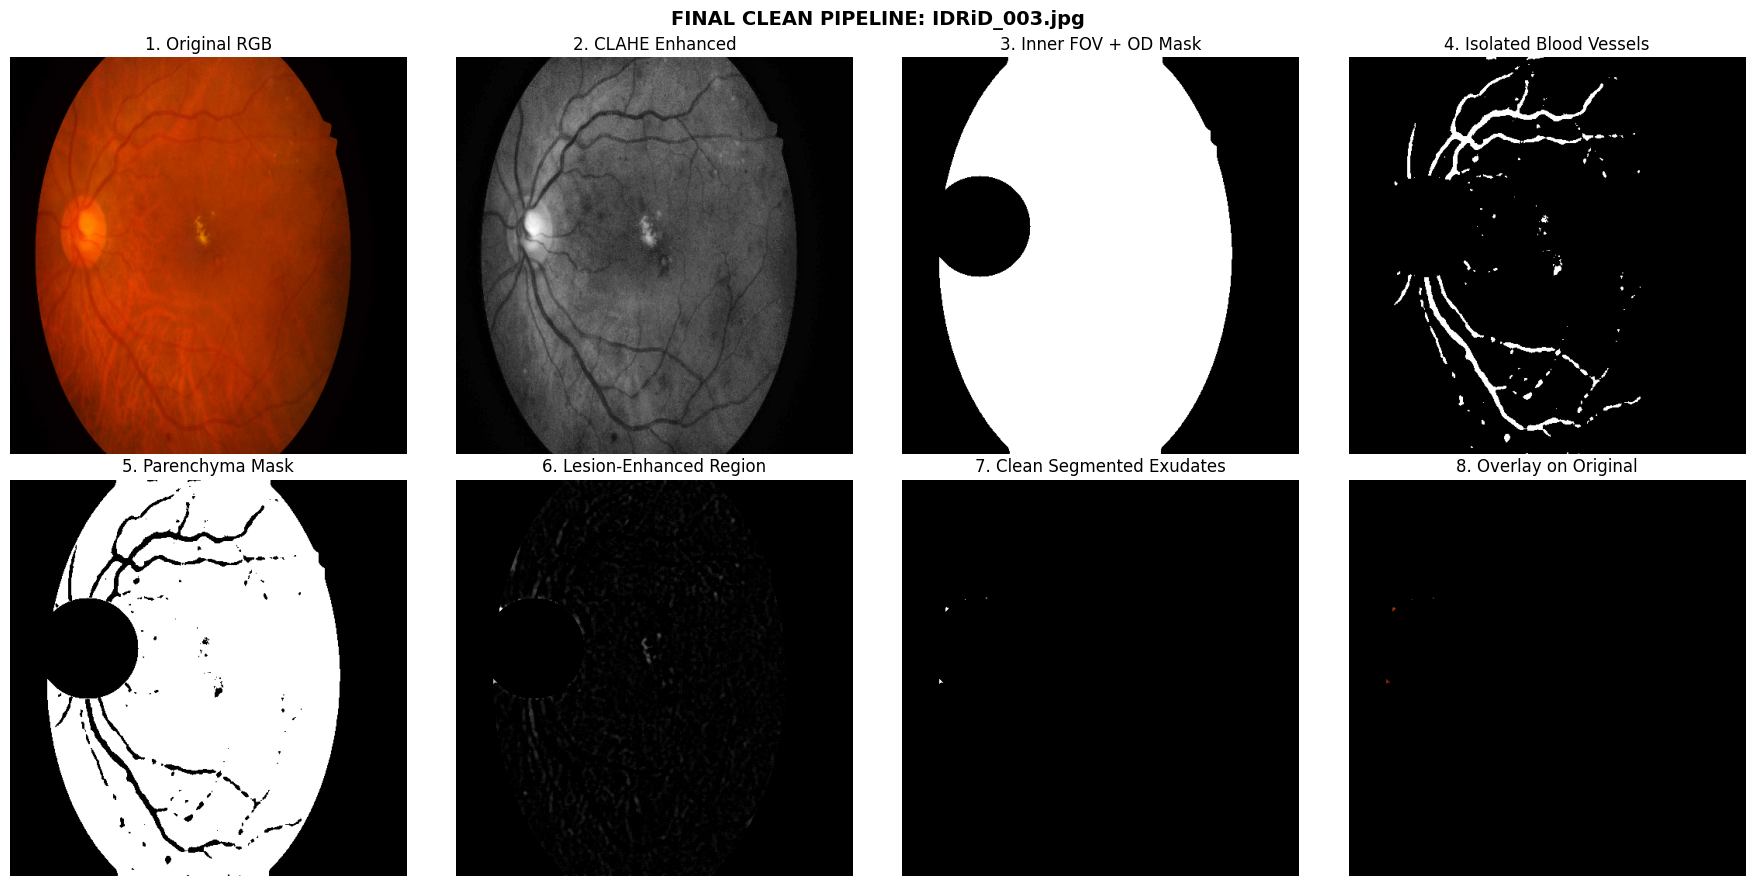

In [4]:
# ==========================================
# CELL: Final Preprocessing Adjuster
# ==========================================
import os
import cv2
import numpy as np
import pywt
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = r"D:\B. Disease Grading"
TRAIN_IMG_DIR = os.path.join(BASE_DIR, "1. Original Images", "a. Training Set")
sample_path = str(sorted(list(Path(TRAIN_IMG_DIR).glob("IDRiD_003.jpg")))[0])

def final_clean_pipeline(img_path):
    img = cv2.imread(img_path)
    resized = cv2.resize(img, (512, 512))
    img_rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
    
    # 1. Green Channel & Enhancement
    green_ch = resized[:, :, 1]
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    enhanced = clahe.apply(green_ch)
    denoised = cv2.medianBlur(enhanced, 5)
    
    # 2. Inner Retinal FOV Mask (Remove border edge noise)
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    kernel_fov = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (30, 30))
    fov_clean = cv2.erode(fov_mask, kernel_fov, iterations=1)
    
    # 3. Expanded Optic Disc Masking (Radius 65 to cover rim halo)
    blur_od = cv2.GaussianBlur(denoised, (25, 25), 0)
    _, _, _, max_loc = cv2.minMaxLoc(blur_od)
    od_mask = np.zeros_like(denoised, dtype=np.uint8)
    cv2.circle(od_mask, max_loc, 65, 255, -1) # Expanded to cover rim
    
    valid_retina_mask = cv2.bitwise_and(fov_clean, cv2.bitwise_not(od_mask))
    retina_masked = cv2.bitwise_and(denoised, denoised, mask=valid_retina_mask)
    
    # 4. Blood Vessel Suppression
    kernel_vessel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    vessel_morph = cv2.morphologyEx(retina_masked, cv2.MORPH_BLACKHAT, kernel_vessel)
    _, vessel_mask = cv2.threshold(vessel_morph, 15, 255, cv2.THRESH_BINARY)
    non_vessel_mask = cv2.bitwise_and(valid_retina_mask, cv2.bitwise_not(vessel_mask))
    
    # 5. Targeted Lesion Extraction
    kernel_lesion = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    top_hat = cv2.morphologyEx(retina_masked, cv2.MORPH_TOPHAT, kernel_lesion)
    top_hat_clean = cv2.bitwise_and(top_hat, top_hat, mask=non_vessel_mask)
    _, exudates_clean = cv2.threshold(top_hat_clean, 35, 255, cv2.THRESH_BINARY)
    
    # Visualization Matrix
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    fig.suptitle("FINAL CLEAN PIPELINE: IDRiD_003.jpg", fontsize=14, fontweight='bold')

    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title("1. Original RGB")

    axes[0, 1].imshow(enhanced, cmap='gray')
    axes[0, 1].set_title("2. CLAHE Enhanced")

    axes[0, 2].imshow(valid_retina_mask, cmap='gray')
    axes[0, 2].set_title("3. Inner FOV + OD Mask")

    axes[0, 3].imshow(vessel_mask, cmap='gray')
    axes[0, 3].set_title("4. Isolated Blood Vessels")

    axes[1, 0].imshow(non_vessel_mask, cmap='gray')
    axes[1, 0].set_title("5. Parenchyma Mask")

    axes[1, 1].imshow(top_hat_clean, cmap='gray')
    axes[1, 1].set_title("6. Lesion-Enhanced Region")

    axes[1, 2].imshow(exudates_clean, cmap='gray')
    axes[1, 2].set_title("7. Clean Segmented Exudates")

    axes[1, 3].imshow(cv2.bitwise_and(resized, resized, mask=exudates_clean)[:, :, ::-1])
    axes[1, 3].set_title("8. Overlay on Original")

    for ax in axes.ravel():
        ax.axis('off')

    plt.tight_layout()
    plt.show()

final_clean_pipeline(sample_path)

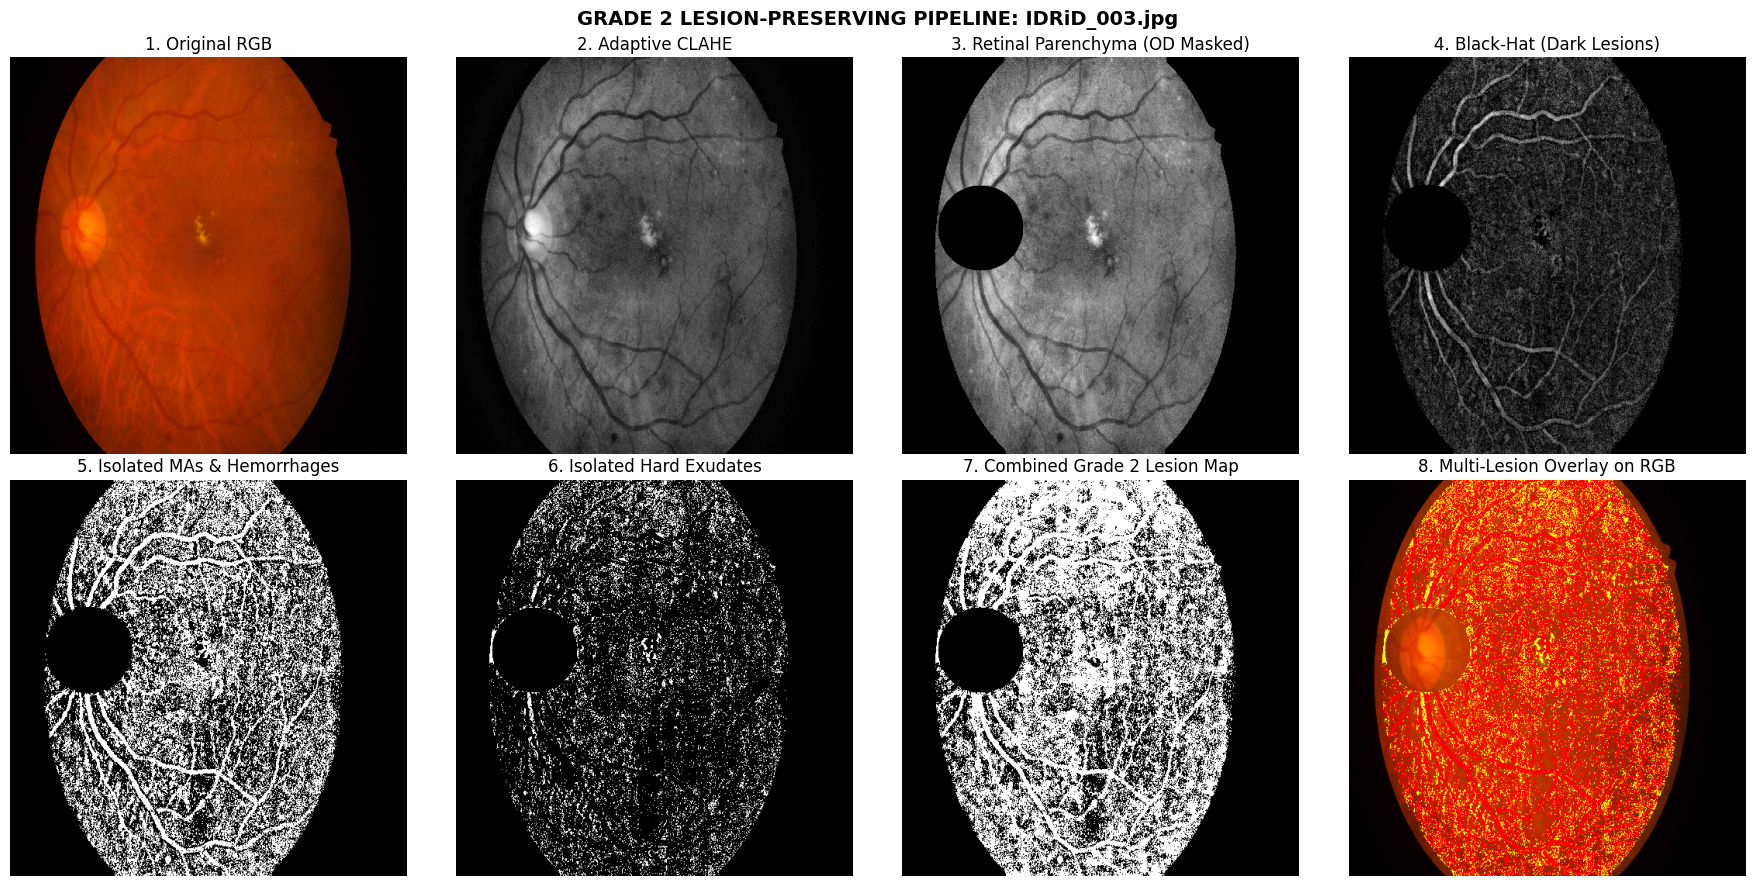

In [1]:
# ==========================================
# CELL: Grade 2 Specific Lesion Visualizer
# ==========================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = r"D:\B. Disease Grading"
TRAIN_IMG_DIR = os.path.join(BASE_DIR, "1. Original Images", "a. Training Set")
sample_path = str(sorted(list(Path(TRAIN_IMG_DIR).glob("IDRiD_003.jpg")))[0])

def visualize_grade2_lesions(img_path):
    img = cv2.imread(img_path)
    resized = cv2.resize(img, (512, 512))
    img_rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
    
    # 1. Green Channel & Adaptive Contrast Enhancement
    green_ch = resized[:, :, 1]
    clahe = cv2.createCLAHE(clipLimit=3.5, tileGridSize=(8, 8))
    enhanced = clahe.apply(green_ch)
    
    # 2. FOV Boundary & Optic Disc Removal
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    kernel_fov = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (20, 20))
    fov_clean = cv2.erode(fov_mask, kernel_fov, iterations=1)
    
    blur_od = cv2.GaussianBlur(enhanced, (25, 25), 0)
    _, _, _, max_loc = cv2.minMaxLoc(blur_od)
    od_mask = np.zeros_like(enhanced, dtype=np.uint8)
    cv2.circle(od_mask, max_loc, 55, 255, -1)
    
    valid_retina_mask = cv2.bitwise_and(fov_clean, cv2.bitwise_not(od_mask))
    retina_masked = cv2.bitwise_and(enhanced, enhanced, mask=valid_retina_mask)
    
    # 3. Microaneurysm & Hemorrhage Extraction (Dark Lesions - Crucial for Grade 2)
    kernel_dark = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    black_hat = cv2.morphologyEx(retina_masked, cv2.MORPH_BLACKHAT, kernel_dark)
    black_hat_masked = cv2.bitwise_and(black_hat, black_hat, mask=valid_retina_mask)
    
    # Sensitive thresholding to capture tiny MAs
    _, dark_lesion_mask = cv2.threshold(black_hat_masked, 12, 255, cv2.THRESH_BINARY)
    
    # 4. Hard Exudate Extraction (Bright Lesions)
    kernel_bright = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    top_hat = cv2.morphologyEx(retina_masked, cv2.MORPH_TOPHAT, kernel_bright)
    top_hat_masked = cv2.bitwise_and(top_hat, top_hat, mask=valid_retina_mask)
    _, bright_exudate_mask = cv2.threshold(top_hat_masked, 20, 255, cv2.THRESH_BINARY)
    
    # Combined Grade 2 Lesion Map
    combined_lesion_map = cv2.bitwise_or(dark_lesion_mask, bright_exudate_mask)
    
    # Overlay on RGB (Red = Dark Lesions / Microaneurysms, Yellow = Exudates)
    overlay = img_rgb.copy()
    overlay[dark_lesion_mask == 255] = [255, 0, 0]        # Red overlay for MAs/Hemorrhages
    overlay[bright_exudate_mask == 255] = [255, 255, 0]   # Yellow overlay for Hard Exudates

    # Display Inspection Grid
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    fig.suptitle("GRADE 2 LESION-PRESERVING PIPELINE: IDRiD_003.jpg", fontsize=14, fontweight='bold')

    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title("1. Original RGB")

    axes[0, 1].imshow(enhanced, cmap='gray')
    axes[0, 1].set_title("2. Adaptive CLAHE")

    axes[0, 2].imshow(retina_masked, cmap='gray')
    axes[0, 2].set_title("3. Retinal Parenchyma (OD Masked)")

    axes[0, 3].imshow(black_hat_masked, cmap='gray')
    axes[0, 3].set_title("4. Black-Hat (Dark Lesions)")

    axes[1, 0].imshow(dark_lesion_mask, cmap='gray')
    axes[1, 0].set_title("5. Isolated MAs & Hemorrhages")

    axes[1, 1].imshow(bright_exudate_mask, cmap='gray')
    axes[1, 1].set_title("6. Isolated Hard Exudates")

    axes[1, 2].imshow(combined_lesion_map, cmap='gray')
    axes[1, 2].set_title("7. Combined Grade 2 Lesion Map")

    axes[1, 3].imshow(overlay)
    axes[1, 3].set_title("8. Multi-Lesion Overlay on RGB")

    for ax in axes.ravel():
        ax.axis('off')

    plt.tight_layout()
    plt.show()

visualize_grade2_lesions(sample_path)

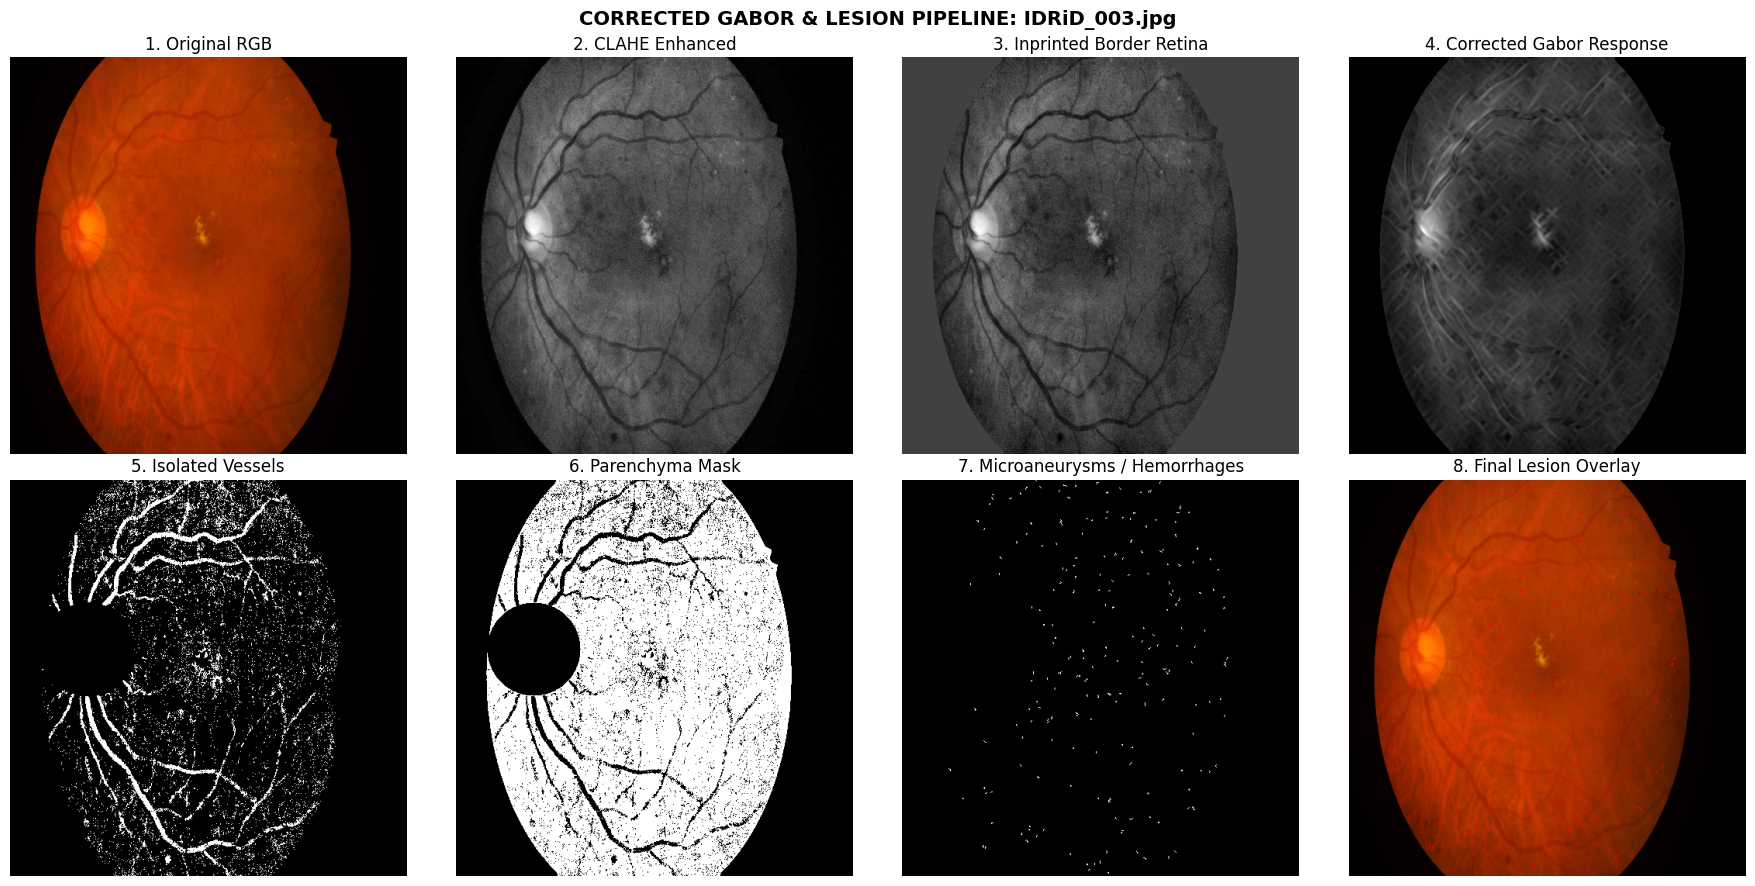

In [6]:
# ==========================================
# CELL 1: Corrected Visual Inspector
# ==========================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = r"D:\B. Disease Grading"
TRAIN_IMG_DIR = os.path.join(BASE_DIR, "1. Original Images", "a. Training Set")
sample_path = str(sorted(list(Path(TRAIN_IMG_DIR).glob("IDRiD_003.jpg")))[0])

def build_gabor_bank():
    filters = []
    # 4 Orientations at 2 scales
    for ksize in [15, 31]:
        for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
            kern = cv2.getGaborKernel((ksize, ksize), 4.0, theta, 10.0, 0.5, 0, ktype=cv2.CV_32F)
            filters.append(kern)
    return filters

def apply_gabor_bank_normalized(img, filters):
    """Applies Gabor filters and normalizes output to 0-255 float range properly."""
    accum = np.zeros(img.shape, dtype=np.float32)
    img_float = img.astype(np.float32) / 255.0
    
    for kern in filters:
        fimg = cv2.filter2D(img_float, cv2.CV_32F, kern)
        accum = np.maximum(accum, np.abs(fimg))
        
    # Min-Max Normalize to uint8 scale
    accum_norm = cv2.normalize(accum, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    return accum_norm.astype(np.uint8)

def pad_fundus_background(green_img, fov_mask):
    mean_val = int(np.mean(green_img[fov_mask == 255]))
    padded = green_img.copy()
    padded[fov_mask == 0] = mean_val
    return padded

def run_visualizer(img_path):
    img = cv2.imread(img_path)
    resized = cv2.resize(img, (512, 512))
    img_rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
    
    # 1. Green Channel & Contrast Enhancement
    green_ch = resized[:, :, 1]
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    enhanced = clahe.apply(green_ch)
    
    # 2. FOV Masking & Outer Border Inpainting
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    kernel_fov = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    fov_clean = cv2.erode(fov_mask, kernel_fov, iterations=1)
    
    padded_retina = pad_fundus_background(enhanced, fov_clean)
    
    # 3. Clean Normalized Gabor Filter Response
    filters = build_gabor_bank()
    gabor_resp = apply_gabor_bank_normalized(padded_retina, filters)
    gabor_resp_masked = cv2.bitwise_and(gabor_resp, gabor_resp, mask=fov_clean)
    
    # 4. Optic Disc Masking
    blur_od = cv2.GaussianBlur(enhanced, (25, 25), 0)
    _, _, _, max_loc = cv2.minMaxLoc(blur_od)
    od_mask = np.zeros_like(enhanced, dtype=np.uint8)
    cv2.circle(od_mask, max_loc, 60, 255, -1)
    
    valid_mask = cv2.bitwise_and(fov_clean, cv2.bitwise_not(od_mask))
    retina_masked = cv2.bitwise_and(enhanced, enhanced, mask=valid_mask)
    
    # 5. Vessel Masking & Lesion Isolation
    kernel_vessel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    vessel_morph = cv2.morphologyEx(retina_masked, cv2.MORPH_BLACKHAT, kernel_vessel)
    _, vessel_mask = cv2.threshold(vessel_morph, 22, 255, cv2.THRESH_BINARY)
    
    non_vessel_mask = cv2.bitwise_and(valid_mask, cv2.bitwise_not(vessel_mask))
    
    kernel_lesion = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    black_hat = cv2.morphologyEx(retina_masked, cv2.MORPH_BLACKHAT, kernel_lesion)
    black_hat_clean = cv2.bitwise_and(black_hat, black_hat, mask=non_vessel_mask)
    _, raw_dark = cv2.threshold(black_hat_clean, 18, 255, cv2.THRESH_BINARY)
    
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(raw_dark)
    dark_lesions = np.zeros_like(raw_dark)
    for i in range(1, num_labels):
        if 3 <= stats[i, cv2.CC_STAT_AREA] <= 100:
            dark_lesions[labels == i] = 255
            
    overlay = img_rgb.copy()
    overlay[dark_lesions == 255] = [255, 0, 0]
    
    # Plot Visual Inspection Grid
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    fig.suptitle("CORRECTED GABOR & LESION PIPELINE: IDRiD_003.jpg", fontsize=14, fontweight='bold')

    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title("1. Original RGB")

    axes[0, 1].imshow(enhanced, cmap='gray')
    axes[0, 1].set_title("2. CLAHE Enhanced")

    axes[0, 2].imshow(padded_retina, cmap='gray')
    axes[0, 2].set_title("3. Inprinted Border Retina")

    axes[0, 3].imshow(gabor_resp_masked, cmap='gray')
    axes[0, 3].set_title("4. Corrected Gabor Response")

    axes[1, 0].imshow(vessel_mask, cmap='gray')
    axes[1, 0].set_title("5. Isolated Vessels")

    axes[1, 1].imshow(non_vessel_mask, cmap='gray')
    axes[1, 1].set_title("6. Parenchyma Mask")

    axes[1, 2].imshow(dark_lesions, cmap='gray')
    axes[1, 2].set_title("7. Microaneurysms / Hemorrhages")

    axes[1, 3].imshow(overlay)
    axes[1, 3].set_title("8. Final Lesion Overlay")

    for ax in axes.ravel():
        ax.axis('off')

    plt.tight_layout()
    plt.show()

run_visualizer(sample_path)

In [7]:
# ==========================================
# CELL 2: Feature Extraction & Classification
# ==========================================
import os
import re
import glob
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from skimage.feature import graycomatrix, graycoprops
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix

BASE_DIR = r"D:\B. Disease Grading"
GROUNDTRUTHS_DIR = os.path.join(BASE_DIR, "2. Groundtruths")
TRAIN_IMG_DIR = os.path.join(BASE_DIR, "1. Original Images", "a. Training Set")
TEST_IMG_DIR = os.path.join(BASE_DIR, "1. Original Images", "b. Testing Set")

def extract_comprehensive_features(img_path):
    img = cv2.imread(str(img_path))
    if img is None:
        return None
    
    resized = cv2.resize(img, (512, 512))
    green_ch = resized[:, :, 1]
    
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    enhanced = clahe.apply(green_ch)
    
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    kernel_fov = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    fov_clean = cv2.erode(fov_mask, kernel_fov, iterations=1)
    
    # Border Inpainting
    mean_val = int(np.mean(enhanced[fov_clean == 255]))
    padded_retina = enhanced.copy()
    padded_retina[fov_clean == 0] = mean_val
    
    # Gabor Features
    filters = build_gabor_bank()
    gabor_resp = apply_gabor_bank_normalized(padded_retina, filters)
    gabor_resp_masked = cv2.bitwise_and(gabor_resp, gabor_resp, mask=fov_clean)
    
    gabor_mean = np.mean(gabor_resp_masked[fov_clean == 255])
    gabor_std = np.std(gabor_resp_masked[fov_clean == 255])
    
    # Optic Disc & Vessels
    blur_od = cv2.GaussianBlur(enhanced, (25, 25), 0)
    _, _, _, max_loc = cv2.minMaxLoc(blur_od)
    od_mask = np.zeros_like(enhanced, dtype=np.uint8)
    cv2.circle(od_mask, max_loc, 60, 255, -1)
    
    valid_mask = cv2.bitwise_and(fov_clean, cv2.bitwise_not(od_mask))
    retina_masked = cv2.bitwise_and(enhanced, enhanced, mask=valid_mask)
    
    kernel_vessel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    vessel_morph = cv2.morphologyEx(retina_masked, cv2.MORPH_BLACKHAT, kernel_vessel)
    _, vessel_mask = cv2.threshold(vessel_morph, 22, 255, cv2.THRESH_BINARY)
    non_vessel_mask = cv2.bitwise_and(valid_mask, cv2.bitwise_not(vessel_mask))
    
    # Lesion Segmentation (Hard Exudates & MAs)
    kernel_lesion = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    top_hat = cv2.morphologyEx(retina_masked, cv2.MORPH_TOPHAT, kernel_lesion)
    top_hat_clean = cv2.bitwise_and(top_hat, top_hat, mask=non_vessel_mask)
    _, exudates = cv2.threshold(top_hat_clean, 25, 255, cv2.THRESH_BINARY)
    ex_area = np.sum(exudates == 255)
    ex_count = cv2.connectedComponents(exudates)[0] - 1
    
    black_hat = cv2.morphologyEx(retina_masked, cv2.MORPH_BLACKHAT, kernel_lesion)
    black_hat_clean = cv2.bitwise_and(black_hat, black_hat, mask=non_vessel_mask)
    _, raw_dark = cv2.threshold(black_hat_clean, 18, 255, cv2.THRESH_BINARY)
    
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(raw_dark)
    dark_lesions = np.zeros_like(raw_dark)
    for i in range(1, num_labels):
        if 3 <= stats[i, cv2.CC_STAT_AREA] <= 100:
            dark_lesions[labels == i] = 255
            
    ma_area = np.sum(dark_lesions == 255)
    ma_count = cv2.connectedComponents(dark_lesions)[0] - 1
    
    # Intensity Statistics
    retina_pixels = retina_masked[valid_mask == 255]
    mean_intensity = np.mean(retina_pixels)
    std_intensity = np.std(retina_pixels)
    skew_intensity = np.mean((retina_pixels - mean_intensity) ** 3) / (std_intensity ** 3 + 1e-6)
    
    # GLCM Metrics
    glcm = graycomatrix(retina_masked, distances=[1, 3], angles=[0, np.pi/4], levels=256, symmetric=True, normed=True)
    contrast = np.mean(graycoprops(glcm, 'contrast'))
    dissimilarity = np.mean(graycoprops(glcm, 'dissimilarity'))
    homogeneity = np.mean(graycoprops(glcm, 'homogeneity'))
    energy = np.mean(graycoprops(glcm, 'energy'))
    correlation = np.mean(graycoprops(glcm, 'correlation'))
    
    return [
        gabor_mean, gabor_std, ex_area, ex_count, ma_area, ma_count,
        mean_intensity, std_intensity, skew_intensity,
        contrast, dissimilarity, homogeneity, energy, correlation
    ]

def build_dataset(image_dir):
    paths = sorted(list(Path(image_dir).glob("*.jpg")))
    cols = ['Image_Name', 'Gabor_Mean', 'Gabor_Std', 'Ex_Area', 'Ex_Count', 'MA_Area', 'MA_Count',
            'Mean_Int', 'Std_Int', 'Skew_Int', 'Contrast', 'Dissimilarity', 'Homogeneity', 'Energy', 'Correlation']
    records = []
    for p in paths:
        feats = extract_comprehensive_features(p)
        if feats is not None:
            records.append([os.path.basename(p)] + feats)
    return pd.DataFrame(records, columns=cols)

print("Processing 413 Training Set Images...")
df_train_feats = build_dataset(TRAIN_IMG_DIR)

print("Processing 103 Testing Set Images...")
df_test_feats = build_dataset(TEST_IMG_DIR)

# Match Groundtruth Labels
gt_files = glob.glob(os.path.join(GROUNDTRUTHS_DIR, "**", "*.csv"), recursive=True)
train_gt = pd.read_csv([f for f in gt_files if 'train' in os.path.basename(f).lower()][0])
test_gt = pd.read_csv([f for f in gt_files if 'test' in os.path.basename(f).lower()][0])

def extract_id(val):
    m = re.search(r'\d+', str(val))
    return int(m.group()) if m else -1

df_train_feats['ID'] = df_train_feats['Image_Name'].apply(extract_id)
train_gt['ID'] = train_gt.iloc[:, 0].apply(extract_id)

df_test_feats['ID'] = df_test_feats['Image_Name'].apply(extract_id)
test_gt['ID'] = test_gt.iloc[:, 0].apply(extract_id)

train_merged = pd.merge(df_train_feats, train_gt[['ID', train_gt.columns[1]]], on='ID')
test_merged = pd.merge(df_test_feats, test_gt[['ID', test_gt.columns[1]]], on='ID')

feature_cols = [c for c in df_train_feats.columns if c not in ['Image_Name', 'ID']]

X_train = train_merged[feature_cols]
y_train = train_merged.iloc[:, -1]

X_test = test_merged[feature_cols]
y_test = test_merged.iloc[:, -1]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

def calculate_specificity(cm):
    specificities = []
    for i in range(len(cm)):
        tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
        fp = np.sum(np.delete(cm, i, axis=0)[:, i])
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificities.append(spec)
    return np.mean(specificities)

# Models
svm = SVC(kernel='rbf', C=10.0, class_weight='balanced', random_state=42)
svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)

rf = RandomForestClassifier(n_estimators=300, max_depth=10, class_weight='balanced', random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)

# Evaluation
cm_svm = confusion_matrix(y_test, y_pred_svm)
acc_svm = accuracy_score(y_test, y_pred_svm) * 100
sen_svm = recall_score(y_test, y_pred_svm, average='macro') * 100
spec_svm = calculate_specificity(cm_svm) * 100
f1_svm = f1_score(y_test, y_pred_svm, average='macro') * 100

cm_rf = confusion_matrix(y_test, y_pred_rf)
acc_rf = accuracy_score(y_test, y_pred_rf) * 100
sen_rf = recall_score(y_test, y_pred_rf, average='macro') * 100
spec_rf = calculate_specificity(cm_rf) * 100
f1_rf = f1_score(y_test, y_pred_rf, average='macro') * 100

summary_data = {
    'Method': ['SVM Classifier', 'Random Forest Classifier'],
    'Accuracy (%)': [f"{acc_svm:.2f}", f"{acc_rf:.2f}"],
    'Sensitivity (%)': [f"{sen_svm:.2f}", f"{sen_rf:.2f}"],
    'Specificity (%)': [f"{spec_svm:.2f}", f"{spec_rf:.2f}"],
    'F1-Score (%)': [f"{f1_svm:.2f}", f"{f1_rf:.2f}"]
}

print("\n=== FINAL CORRECTED PIPELINE RESULTS ===")
print(pd.DataFrame(summary_data).to_string(index=False))

Processing 413 Training Set Images...
Processing 103 Testing Set Images...

=== FINAL CORRECTED PIPELINE RESULTS ===
                  Method Accuracy (%) Sensitivity (%) Specificity (%) F1-Score (%)
          SVM Classifier        31.07           32.26           82.59        28.66
Random Forest Classifier        22.33           17.26           79.26        17.44
